# PDF parsing with PyMuPDF and OCR

This practical notebook examines what a PDF exposes to a parser and what must be recovered with OCR.

The two inputs serve different purposes:

- `ch2.pdf` is a born-digital slide deck. It contains native text, mathematical notation, vector graphics, raster images, and a table-like layout.
- `scanned.pdf` is a three-page scanned letter. Its first page looks text-rich, but most of that content is stored as an image.

The experiments move from document inspection to text geometry and structure, then compare native extraction with partial and full-page OCR. Coordinates reported by PyMuPDF are in PDF points, where 72 points equal one inch.

## Setup

The notebook uses paths relative to its own directory. PyMuPDF performs parsing and rendering; NumPy and Matplotlib are used only for the two page visualizations. OCR also requires the English Tesseract language file in `tessdata/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pymupdf
from matplotlib.patches import Rectangle

SLIDES_PDF = Path("ch2.pdf")
SCANNED_PDF = Path("scanned.pdf")
TESSDATA_DIR = Path("tessdata")

required_files = [
    SLIDES_PDF,
    SCANNED_PDF,
    TESSDATA_DIR / "eng.traineddata",
]
for path in required_files:
    if not path.exists():
        raise FileNotFoundError(f"Required input not found: {path.resolve()}")

print("PyMuPDF version:", pymupdf.__version__)
print("Inputs:", ", ".join(str(path) for path in required_files))

PyMuPDF version: 2.1
Inputs: ch2.pdf, scanned.pdf, tessdata/eng.traineddata


## 1. Inspect the PDF documents

**Objective.** Compare the basic structure of the two files before extracting content.

**Method.** For each document, inspect the page count, selected metadata, encryption status, table of contents, and first-page geometry. Page rectangles describe the coordinate space used by later text bounding boxes.

In [2]:
for pdf_path in [SLIDES_PDF, SCANNED_PDF]:
    with pymupdf.open(pdf_path) as document:
        metadata = document.metadata
        first_page = document[0]

        print(f"\n{pdf_path.name}")
        print("  Pages:", document.page_count)
        print("  Format:", metadata.get("format"))
        print("  Title:", repr(metadata.get("title")))
        print("  Creator:", repr(metadata.get("creator")))
        print("  Encrypted:", document.is_encrypted)
        print("  Table-of-contents entries:", len(document.get_toc()))
        print("  First-page dimensions:", first_page.rect)
        print("  First-page rotation:", first_page.rotation)


ch2.pdf
  Pages: 68
  Format: PDF 1.5
  Title: 'The prior distribution'
  Creator: 'LaTeX with Beamer class'
  Encrypted: False
  Table-of-contents entries: 5
  First-page dimensions: Rect(0.0, 0.0, 362.8349914550781, 272.1260070800781)
  First-page rotation: 0

scanned.pdf
  Pages: 3
  Format: PDF 1.5
  Title: 'Scanned Document'
  Creator: 'HardCopy'
  Encrypted: False
  Table-of-contents entries: 0
  First-page dimensions: Rect(0.0, 0.0, 612.0, 792.0)
  First-page rotation: 0


**Observation.** `ch2.pdf` has 68 pages, five table-of-contents entries, and a 362.83 × 272.13 point slide page. Its metadata identifies LaTeX with the Beamer class as the creator. `scanned.pdf` has three pages, no table of contents, and a 612 × 792 point first page; its metadata identifies a Lexmark device. Neither file is encrypted, and both first pages have zero rotation.

**Interpretation.** Metadata and geometry provide useful context, but they do not tell us whether visible page content is encoded as searchable text, vectors, or pixels. Content-level inspection is still necessary.

## 2. Native text extraction and reading order

**Objective.** Examine how a born-digital page is converted from positioned glyphs into plain text, especially when it contains mathematical notation.

**Method.** Extract page 9 twice: first in the PDF's stored order and then with `sort=True`, which asks PyMuPDF to reorder text geometrically from top-left to bottom-right.

In [3]:
with pymupdf.open(SLIDES_PDF) as document:
    math_page = document[8]
    default_text = math_page.get_text("text")
    sorted_text = math_page.get_text("text", sort=True)

print("DEFAULT EXTRACTION:\n")
print(default_text)
print("SORTED EXTRACTION:\n")
print(sorted_text)

DEFAULT EXTRACTION:

Why the support of the prior matters. II
• In the dominated case this is Bayes’ rule: π(A|x) =
1
m(x)
R
A f(x|θ)π(θ) dθ = 0
as soon as π(A) =
R
A π(θ) dθ = 0.
• Cromwell’s rule (Lindley 1985): never give prior probability 0 to a possibility
that is not logically impossible. Example: truncating a prior to θ ∈[0, 10] for
convenience excludes θ > 10 forever, however strongly the data point there.
• Quantitative version (same computation): π(A|x) ≤π(A) supθ∈A f(x|θ)/m(x).
A region of small prior mass can be recovered only by a large likelihood ratio.
• Chapter 8 (asymptotic properties): a sufficient condition for posterior
consistency at θ0 is that π gives positive mass to the Kullback-Leibler
neighbourhoods of Pθ0 (Schwartz 1965). This slide shows why positive prior
mass around θ0 is in any case necessary.
The prior distribution
9 / 68

SORTED EXTRACTION:

          Why the support of the prior matters. II



• In the dominated case this is Bayes’ rule: π(A|x) = m(x)1

**Observation.** Both modes recover the slide title, four bullet points, and footer. With `sort=True`, the bullets follow the visual page order more closely, but the first fraction is flattened as `m(x)1` and the integral glyph appears as `R`. The default extraction places the numerator, denominator, and integral components on separate lines.

**Interpretation.** A PDF stores glyphs, fonts, and positions rather than a semantic equation tree. Geometric sorting can improve ordinary reading order, but it cannot reconstruct fractions, limits, subscripts, or other two-dimensional mathematical relationships. The font encoding also determines whether a glyph maps cleanly to Unicode.

## 3. Words and bounding boxes

**Objective.** Connect extracted words to their positions on the rendered page.

**Method.** Request word-level output from page 9. Each tuple contains `(x0, y0, x1, y1, text, block, line, word)`. The first 25 word rectangles are then scaled from PDF points to the 144 dpi raster image and drawn in red.

Total words: 148
Tuple fields: (x0, y0, x1, y1, text, block, line, word)
(127.23300170898438, 9.100998878479004, 155.05027770996094, 23.44719886779785, 'Why', 0, 0, 0)
(158.63682556152344, 9.100998878479004, 176.1678924560547, 23.44719886779785, 'the', 0, 0, 1)
(179.7544403076172, 9.100998878479004, 222.79302978515625, 23.44719886779785, 'support', 0, 0, 2)
(226.37957763671875, 9.100998878479004, 238.3299560546875, 23.44719886779785, 'of', 0, 0, 3)
(241.91650390625, 9.100998878479004, 259.44757080078125, 23.44719886779785, 'the', 0, 0, 4)
(263.03411865234375, 9.100998878479004, 290.9231262207031, 23.44719886779785, 'prior', 0, 0, 5)
(294.5096740722656, 9.100998878479004, 340.3314514160156, 23.44719886779785, 'matters.', 0, 0, 6)
(344.7787780761719, 9.100998878479004, 354.3333435058594, 23.44719886779785, 'II', 0, 0, 7)
(38.68299865722656, 65.0522689819336, 43.29172897338867, 74.01866912841797, '•', 1, 0, 0)
(48.27199935913086, 66.6209716796875, 55.74101257324219, 75.58737182617188, 'In

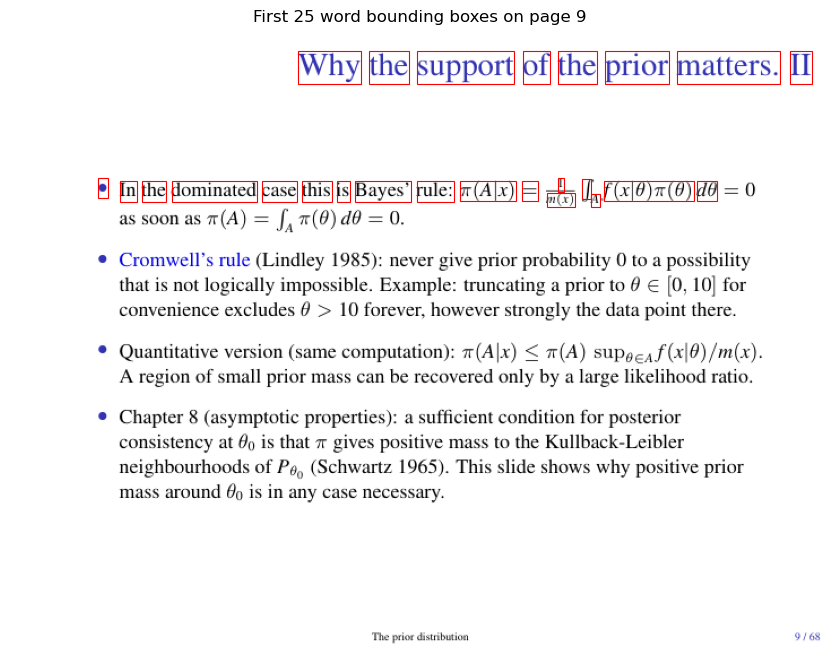

In [4]:
with pymupdf.open(SLIDES_PDF) as document:
    page = document[8]
    words = page.get_text("words")
    pixmap = page.get_pixmap(dpi=144, alpha=False)
    page_rect = page.rect

print("Total words:", len(words))
print("Tuple fields: (x0, y0, x1, y1, text, block, line, word)")
for word in words[:10]:
    print(word)

image = np.frombuffer(pixmap.samples, dtype=np.uint8)
image = image.reshape(pixmap.height, pixmap.stride)[:, : pixmap.width * pixmap.n]
image = image.reshape(pixmap.height, pixmap.width, pixmap.n)

scale_x = pixmap.width / page_rect.width
scale_y = pixmap.height / page_rect.height

fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(image)

for x0, y0, x1, y1, *_ in words[:25]:
    ax.add_patch(
        Rectangle(
            (x0 * scale_x, y0 * scale_y),
            (x1 - x0) * scale_x,
            (y1 - y0) * scale_y,
            fill=False,
            edgecolor="red",
            linewidth=0.8,
        )
    )

ax.set_title("First 25 word bounding boxes on page 9")
ax.axis("off")
plt.show()

**Observation.** PyMuPDF reports 148 words. The first tuple places `Why` at approximately `(127.23, 9.10, 155.05, 23.45)`, followed by the remaining title words on the same line. In the visualization, the red rectangles align with the title and the first bullet, including small formula components.

**Interpretation.** A bounding box is an axis-aligned rectangle around one extracted item in page coordinates. It enables highlighting, region filtering, and layout analysis, but it does not by itself express relationships such as “this glyph is the denominator of that fraction.”

## 4. Blocks, lines, spans, and fonts

**Objective.** Inspect the hierarchy below plain text and explain why the equation is fragmented.

**Method.** Extract the page as a dictionary, count its text blocks, lines, and spans, then display only the first 20 spans. A span groups adjacent characters that share formatting properties such as font and size.

In [5]:
with pymupdf.open(SLIDES_PDF) as document:
    page_dict = document[8].get_text("dict")

text_blocks = [block for block in page_dict["blocks"] if block["type"] == 0]
lines = [line for block in text_blocks for line in block["lines"]]
spans = [span for line in lines for span in line["spans"]]

print("Text blocks:", len(text_blocks))
print("Lines:", len(lines))
print("Spans:", len(spans))
print("\nFirst 20 spans:")

for span in spans[:20]:
    print(
        {
            "text": span["text"],
            "font": span["font"],
            "size": round(span["size"], 2),
            "bbox": tuple(round(value, 2) for value in span["bbox"]),
        }
    )

Text blocks: 10
Lines: 20
Spans: 138

First 20 spans:
{'text': 'Why the support of the prior matters.', 'font': 'NimbusRomNo9L-Regu', 'size': 14.35, 'bbox': (127.23, 9.1, 340.33, 23.45)}
{'text': ' ', 'font': 'NimbusRomNo9L-Regu', 'size': 14.35, 'bbox': (340.33, 9.1, 344.78, 23.45)}
{'text': 'II', 'font': 'NimbusRomNo9L-Regu', 'size': 14.35, 'bbox': (344.78, 9.1, 354.33, 23.45)}
{'text': '•', 'font': 'CMSY9', 'size': 8.97, 'bbox': (38.68, 65.05, 43.29, 74.02)}
{'text': ' ', 'font': 'NimbusRomNo9L-Regu', 'size': 8.97, 'bbox': (43.29, 65.38, 48.27, 74.34)}
{'text': 'In the dominated case this is Bayes’ rule:', 'font': 'NimbusRomNo9L-Regu', 'size': 8.97, 'bbox': (48.27, 66.62, 195.95, 75.59)}
{'text': ' ', 'font': 'CMMI9', 'size': 8.97, 'bbox': (195.95, 66.41, 198.73, 75.38)}
{'text': 'π', 'font': 'CMMI9', 'size': 8.97, 'bbox': (198.73, 66.41, 204.0, 75.38)}
{'text': '(', 'font': 'CMR9', 'size': 8.97, 'bbox': (204.32, 66.41, 207.91, 75.38)}
{'text': 'A', 'font': 'NimbusRomNo9L-ReguItal', 

**Observation.** Page 9 contains 10 text blocks, 20 lines, and 138 spans. The title is mostly one 14.35-point span, whereas the first equation is split across several fonts and sizes. For example, the numerator `1` and denominator components use 5.98-point spans at different vertical positions, while the surrounding equation uses 8.97-point spans.

**Interpretation.** The block → line → span hierarchy preserves more layout and typography than plain text. The same detail explains the extraction problem: the fraction is represented by separately positioned spans, so flattening them into a character sequence discards their mathematical relationship.

## 5. Raster images, vector drawings, and tables

**Objective.** Compare three forms of complex page content.

**Method.** Inspect pages 17, 49, and 65 of the slide deck. `get_images(full=True)` counts embedded raster image objects, `get_drawings()` returns vector paths, and `find_tables()` looks for table structure from page geometry and text alignment.

In [6]:
with pymupdf.open(SLIDES_PDF) as document:
    for page_number in [17, 49, 65]:
        page = document[page_number - 1]
        detected_tables = page.find_tables().tables

        print(f"Page {page_number}")
        print("  Words:", len(page.get_text("words")))
        print("  Raster images:", len(page.get_images(full=True)))
        print("  Vector drawings:", len(page.get_drawings()))
        print("  Detected tables:", len(detected_tables))

Page 17
  Words: 167
  Raster images: 0
  Vector drawings: 67
  Detected tables: 0
Page 49
  Words: 216
  Raster images: 0
  Vector drawings: 10
  Detected tables: 1


Page 65
  Words: 39
  Raster images: 2
  Vector drawings: 2
  Detected tables: 0


**Observation.** Page 17 has 167 words, no raster images, 67 vector drawings, and no detected table; its two plots are drawn from vector paths. Page 49 has 216 words, 10 vector drawings, and one detected table. Page 65 has 39 words, two raster images, two vector drawings, and no detected table.

**Interpretation.** Raster images store pixels, while vector drawings store geometric instructions such as lines and curves; a visible plot can therefore appear in either category. Table detection succeeds on page 49 because its aligned rows, columns, and rules form a table-like structure. The plot paths on page 17 do not form that structure, and the plot on page 65 is embedded mainly as raster content, whose internal pixels are not table geometry for `find_tables()`.

## 6. Visible text versus extractable text in a scan

**Objective.** Show why a page that visibly contains paragraphs may expose almost no native text.

**Method.** Render page 1 of `scanned.pdf`, then compare the visible page with its native text extraction and embedded-image count.

Number of pages: 3
Native text: 'SAMPLE LETTER\n'
Embedded images on page 1: 1
Page dimensions: Rect(0.0, 0.0, 612.0, 792.0)


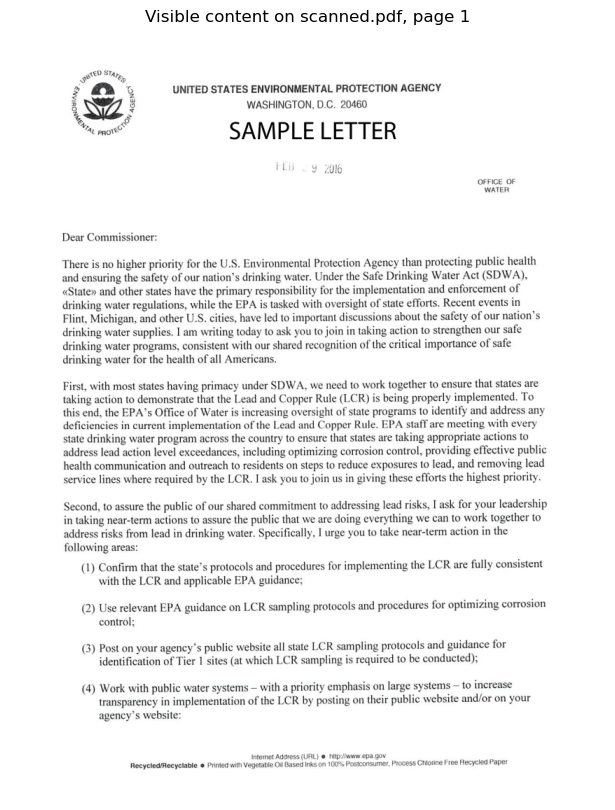

In [7]:
with pymupdf.open(SCANNED_PDF) as document:
    scanned_page = document[0]
    page_count = document.page_count
    page_rect = scanned_page.rect
    native_text = scanned_page.get_text("text")
    embedded_images = len(scanned_page.get_images(full=True))
    scan_pixmap = scanned_page.get_pixmap(dpi=100, alpha=False)

print("Number of pages:", page_count)
print("Native text:", repr(native_text))
print("Embedded images on page 1:", embedded_images)
print("Page dimensions:", page_rect)

scan_image = np.frombuffer(scan_pixmap.samples, dtype=np.uint8)
scan_image = scan_image.reshape(
    scan_pixmap.height, scan_pixmap.stride
)[:, : scan_pixmap.width * scan_pixmap.n]
scan_image = scan_image.reshape(
    scan_pixmap.height, scan_pixmap.width, scan_pixmap.n
)

fig, ax = plt.subplots(figsize=(8, 10))
ax.imshow(scan_image)
ax.set_title("Visible content on scanned.pdf, page 1")
ax.axis("off")
plt.show()

**Observation.** The rendered page visibly contains an agency header, a date, and several paragraphs. Native extraction returns only `'SAMPLE LETTER\n'`, while the page contains one embedded image.

**Interpretation.** Most of the letter is represented by image pixels rather than character objects. The phrase `SAMPLE LETTER` is a small native text layer placed over the scan, so ordinary extraction can recover it but cannot read the surrounding pixels. OCR is required for the rest.

## 7. Partial and full-page OCR

**Objective.** Compare native extraction with PyMuPDF's two OCR modes on the scanned page.

**Method.** At 200 dpi, `full=False` keeps readable native text and applies OCR to the remaining page regions. `full=True` renders and OCRs the entire page, including areas that already contain native text. The returned `TextPage` is passed back to `get_text()` for extraction.

In [8]:
with pymupdf.open(SCANNED_PDF) as document:
    page = document[0]
    native_text = page.get_text("text")

    partial_textpage = page.get_textpage_ocr(
        language="eng",
        dpi=200,
        full=False,
        tessdata=str(TESSDATA_DIR),
    )
    full_textpage = page.get_textpage_ocr(
        language="eng",
        dpi=200,
        full=True,
        tessdata=str(TESSDATA_DIR),
    )

    partial_text = page.get_text("text", textpage=partial_textpage)
    full_text = page.get_text("text", textpage=full_textpage)

print("NATIVE EXTRACTION:\n", repr(native_text), sep="")
print("\nPARTIAL OCR (first 500 characters):\n")
print(partial_text[:500])
print("\nFULL OCR (first 500 characters):\n")
print(full_text[:500])

NATIVE EXTRACTION:
'SAMPLE LETTER\n'

PARTIAL OCR (first 500 characters):

SAMPLE LETTER
se STA.
2 re \ i}
UNITED STATES ENVIRONMENTAL PROTECTION AGENCY
3SZ &
WASHINGTON, D.C. 20460
&,
eo
AL pro
PE.
y
2016
OFFICE OF
WATER
Dear Commissioner:
There is no higher priority for the U.S. Environmental Protection Agency than protecting public health
and ensuring the safety of our nation’s drinking water. Under the Safe Drinking Water Act (SDWA),
«State» and other states have the primary responsibility for the implementation and enforcement of
drinking water regulations, while 

FULL OCR (first 500 characters):

ee ore,
2 re \ i}
UNITED STATES ENVIRONMENTAL PROTECTION AGENCY
3SZ 8
WASHINGTON, D.C. 20460
b,
=
%,
KS
“emo
SAMPLE LETTER
FEN.
9
2016
OFFICE OF
WATER
Dear Commissioner:
There is no higher priority for the U.S. Environmental Protection Agency than protecting public health
and ensuring the safety of our nation’s drinking water. Under the Safe Drinking Water Act (SDWA),
«State» and other 

**Observation.** Partial OCR begins with the preserved native phrase `SAMPLE LETTER`, then adds OCR text from the scanned regions. Full OCR begins with noisy fragments such as `ee ore,` before recovering the agency name, address, `SAMPLE LETTER`, and the body. Both modes recover coherent prose, but both misread parts of the circular logo and the faint date; examples include isolated symbols and fragments such as `FEN.` and `2016` on separate lines.

**Interpretation.** Partial OCR combines reliable native text with OCR only where native text is absent, so it preserves `SAMPLE LETTER` exactly and can produce a different reading order. Full OCR treats the entire rendered page as pixels, so even existing text is re-recognized. Logos resemble characters without forming words, and faint or low-contrast marks provide weak visual evidence; these regions are therefore especially prone to OCR substitutions and spurious text.

## 8. Key findings and limitations

- Native PDFs expose text, coordinates, fonts, vector paths, and images, but not necessarily the semantic structure a reader perceives.
- `sort=True` improves geometric reading order; it does not reconstruct mathematical notation.
- Word bounding boxes locate text, while blocks, lines, and spans preserve progressively finer layout and typography.
- Visually similar figures may be vector drawings or raster images. Table detection depends on recoverable page geometry and aligned text, not appearance alone.
- A scanned page may contain only a small native text layer. Partial OCR preserves that layer; full OCR reprocesses the whole page image.
- OCR quality is region-dependent. Stylized logos, faint characters, and complex layouts can create noise even when the main body is readable.

These results are specific to the selected pages, PyMuPDF version, English OCR model, and 200 dpi setting. Different PDFs, encodings, page layouts, languages, or OCR resolutions can produce different extraction order and accuracy.